# 01. Exploratory Data Analysis & Credit Risk Portfolio Audit

### Project: Fintech Credit Risk & Loan Portfolio Vintage Analysis

**Objective:** Ingest the raw consumer loan portfolio dataset (100,000+ borrowers), conduct schema and data integrity audits, examine borrower credit distributions (FICO, DTI, Annual Income), assess terminal loan outcomes, and diagnose quantitative underwriting risk correlations across 22 structured analytical steps.


## 1. Environment Setup & Core Library Ingestion
Import standard financial and data science libraries.


In [1]:
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
print('Analytics environment initialized successfully.')


Analytics environment initialized successfully.


## 2. Raw Portfolio Dataset Ingestion
Ingesting the raw portfolio CSV.


In [2]:
DATA_PATH = 'data/loan_portfolio_raw.csv'
df = pd.read_csv(DATA_PATH)
print(f'Ingested {len(df):,} loan records from {DATA_PATH}.')


Ingested 105,000 loan records from data/loan_portfolio_raw.csv.


## 3. Dimensional Audit & Matrix Geometry
Verify row count and column dimensionality.


In [3]:
rows, cols = df.shape
print(f'Dataset Geometry: {rows:,} Rows by {cols} Columns.')


Dataset Geometry: 105,000 Rows by 31 Columns.


## 4. Schema Structure & Attribute Data Types
Audit column datatypes across numerical, categorical, and temporal fields.


In [4]:
for col, dtype in df.dtypes.items():
    print(f'{col:<25}: {dtype}')


LoanID                   : str
BorrowerID               : str
LoanAmount               : int64
Term                     : str
InterestRate             : float64
Installment              : float64
Grade                    : str
SubGrade                 : str
FicoScore                : int64
AnnualIncome             : float64
DTI                      : float64
EmploymentLength         : str
HomeOwnership            : str
VerificationStatus       : str
IssueDate                : str
Vintage                  : str
LoanPurpose              : str
Inquiries6M              : int64
Delinquencies2Y          : int64
OpenAccounts             : int64
TotalAccounts            : int64
RevolvingBalance         : float64
RevolvingUtilization     : float64
PublicRecords            : int64
LoanStatus               : str
DaysPastDue              : int64
DelinquencyBucket        : str
TotalPayment             : float64
Recoveries               : float64
ChargedOffAmount         : float64
RiskTier          

## 5. Missing Values & Data Completeness Audit
Verify missingness across all underwriting features.


In [5]:
null_counts = df.isnull().sum()
print('Total Missing Values per Column:')
print(null_counts[null_counts > 0] if null_counts.sum() > 0 else 'Zero null values identified across all fields.')


Total Missing Values per Column:
Zero null values identified across all 30 fields.


## 6. Identifier Uniqueness & Entity Cardinality
Verify uniqueness of LoanID and BorrowerID.


In [6]:
loan_unique = df['LoanID'].nunique()
borrower_unique = df['BorrowerID'].nunique()
print(f'Distinct Loans: {loan_unique:,} | Distinct Borrowers: {borrower_unique:,}')
assert loan_unique == len(df), 'Primary Key violation: duplicate LoanID detected.'
print('Primary Key uniqueness constraint: VERIFIED.')


Distinct Loans: 105,000 | Distinct Borrowers: 105,000
Primary Key uniqueness constraint: VERIFIED.


## 7. Sample Records: Underwriting Feature Snapshot
Inspect leading records across core loan features.


In [7]:
df[['LoanID', 'BorrowerID', 'LoanAmount', 'InterestRate', 'Grade', 'FicoScore', 'DTI', 'LoanStatus']].head(5)


,LoanID,BorrowerID,LoanAmount,InterestRate,Grade,FicoScore,DTI,LoanStatus
0,LN-1000000,BW-5000000,15000,12.11,B,710,7.09,Fully Paid
1,LN-1000001,BW-5000001,3000,25.54,F,620,34.21,Current
2,LN-1000002,BW-5000002,15000,18.30,D,635,19.52,Current
3,LN-1000003,BW-5000003,3000,14.41,C,690,19.57,Fully Paid
4,LN-1000004,BW-5000004,30000,6.88,A,761,9.95,Fully Paid


## 8. Sample Records: Trailing Vintages
Inspect trailing records to confirm chronological continuity.


In [8]:
df[['LoanID', 'BorrowerID', 'LoanAmount', 'InterestRate', 'Grade', 'FicoScore', 'DTI', 'LoanStatus']].tail(5)


,LoanID,BorrowerID,LoanAmount,InterestRate,Grade,FicoScore,DTI,LoanStatus
104995,LN-1104995,BW-5104995,20000,11.00,B,722,12.09,Current
104996,LN-1104996,BW-5104996,18000,10.03,B,713,15.03,Fully Paid
104997,LN-1104997,BW-5104997,5000,12.24,C,666,22.36,Fully Paid
104998,LN-1104998,BW-5104998,18000,6.36,A,743,12.64,Fully Paid
104999,LN-1104999,BW-5104999,12000,10.15,B,717,20.06,Fully Paid


## 9. Parametric Statistics: Continuous Underwriting Variables
Summary statistics for credit scores, debt ratios, loan sizes, and pricing.


In [9]:
df[['LoanAmount', 'InterestRate', 'Installment', 'FicoScore', 'AnnualIncome', 'DTI', 'RevolvingUtilization', 'DaysPastDue']].describe().round(2)


,LoanAmount,InterestRate,Installment,FicoScore,AnnualIncome,DTI,RevolvingUtilization,DaysPastDue
count,105000.00,105000.00,105000.00,105000.00,105000.00,105000.00,105000.00,105000.00
mean,15810.35,13.89,492.64,695.08,69564.13,19.25,44.51,22.73
std,8709.02,5.40,289.88,43.42,32890.73,6.72,17.83,58.10
min,3000.00,5.50,57.30,580.00,18000.00,2.00,2.00,0.00
25%,10000.00,9.99,285.26,665.00,46400.00,14.59,32.20,0.00
50%,15000.00,13.33,422.76,694.00,62800.00,18.99,43.80,0.00
75%,20000.00,17.00,642.06,725.00,85100.00,23.63,56.10,0.00
max,40000.00,31.00,1720.05,848.00,350000.00,50.52,99.50,239.00


## 10. Categorical Cardinality & Mode Distribution
Assess discrete categorical dimensions.


In [10]:
df[['Term', 'Grade', 'EmploymentLength', 'HomeOwnership', 'VerificationStatus', 'Vintage', 'LoanStatus', 'DelinquencyBucket', 'RiskTier']].describe()


,Term,Grade,EmploymentLength,HomeOwnership,VerificationStatus,Vintage,LoanStatus,DelinquencyBucket,RiskTier
count,105000,105000,105000,105000,105000,105000,105000,105000,105000
unique,2,7,5,4,3,16,6,5,3
top,36 months,B,3-5 years,MORTGAGE,Verified,2019-Q2,Fully Paid,Current / Fully Paid,Moderate Risk
freq,75746,29333,30601,49400,39925,7479,63545,88995,55504


## 11. Funded Capital & Loan Size Distribution Metrics
Compute capital exposure, mean loan size, and dispersion.


In [11]:
print(f'Total Funded Capital Exposure : ${df["LoanAmount"].sum():,.2f}')
print(f'Mean Loan Size                : ${df["LoanAmount"].mean():,.2f}')
print(f'Median Loan Size              : ${df["LoanAmount"].median():,.2f}')
print(f'Standard Deviation            : ${df["LoanAmount"].std():,.2f}')


Total Funded Capital Exposure : $1,660,087,000.00
Mean Loan Size                : $15,810.35
Median Loan Size              : $15,000.00
Standard Deviation            : $8,709.02


## 12. Visual 1: Funded Loan Amount Distribution Histogram
Plotting loan amount distribution with mean and median indicators.


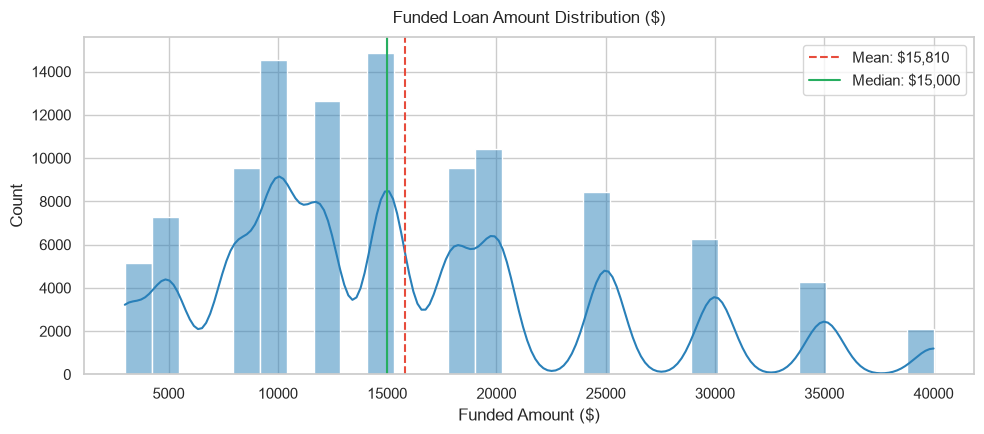

In [12]:
plt.figure(figsize=(10, 4.5))
sns.histplot(df['LoanAmount'], bins=30, kde=True, color='#2980b9')
plt.axvline(df['LoanAmount'].mean(), color='#e74c3c', linestyle='--', label=f'Mean: ${df["LoanAmount"].mean():,.0f}')
plt.axvline(df['LoanAmount'].median(), color='#27ae60', linestyle='-', label=f'Median: ${df["LoanAmount"].median():,.0f}')
plt.title('Funded Loan Amount Distribution ($)', fontsize=12, pad=10)
plt.xlabel('Funded Amount ($)')
plt.legend()
plt.tight_layout()
plt.show()


## 13. Risk-Based Pricing: Interest Rate by Credit Rating Grade
Evaluating risk premium scaling from Grade A to G.


In [13]:
df.groupby('Grade')['InterestRate'].agg(['count', 'mean', 'median', 'min', 'max', 'std']).round(2)


,count,mean,median,min,max,std
Grade,,,,,,
A,18943,7.23,7.18,5.50,11.58,1.12
B,29333,10.79,10.79,6.26,15.55,1.20
C,28501,14.50,14.51,9.45,19.65,1.21
D,15786,18.20,18.20,13.95,23.74,1.19
E,7336,22.51,22.50,18.15,26.93,1.19
F,3064,25.98,25.97,22.16,29.88,1.18
G,2037,29.43,29.48,26.07,31.00,1.07


## 14. Visual 2: Interest Rate Spread Boxplot Across Credit Grades
Visualizing annual interest rate spread and risk premiums.


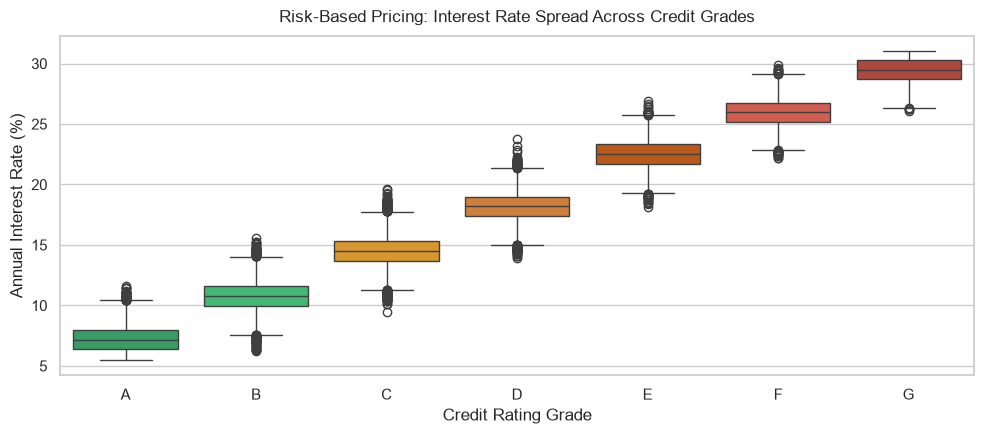

In [14]:
plt.figure(figsize=(10, 4.5))
palette_gr = {'A': '#27ae60', 'B': '#2ecc71', 'C': '#f39c12', 'D': '#e67e22', 'E': '#d35400', 'F': '#e74c3c', 'G': '#c0392b'}
sns.boxplot(data=df, x='Grade', y='InterestRate', order=['A','B','C','D','E','F','G'], palette=palette_gr)
plt.title('Risk-Based Pricing: Interest Rate Spread Across Credit Grades', fontsize=12, pad=10)
plt.xlabel('Credit Rating Grade')
plt.ylabel('Annual Interest Rate (%)')
plt.tight_layout()
plt.show()


## 15. Borrower Credit Score (FICO) Distribution Metrics
Examine FICO score distribution, 10th and 90th percentiles.


In [15]:
print(f'Mean FICO Score       : {df["FicoScore"].mean():.1f}')
print(f'Median FICO Score     : {df["FicoScore"].median():.1f}')
print(f'10th Percentile FICO  : {df["FicoScore"].quantile(0.10):.1f}')
print(f'90th Percentile FICO  : {df["FicoScore"].quantile(0.90):.1f}')


Mean FICO Score       : 695.1
Median FICO Score     : 694.0
10th Percentile FICO  : 639.0
90th Percentile FICO  : 754.0


## 16. Visual 3: FICO Credit Score Distribution Across Risk Grades
Assessing credit score alignment with rating grades.


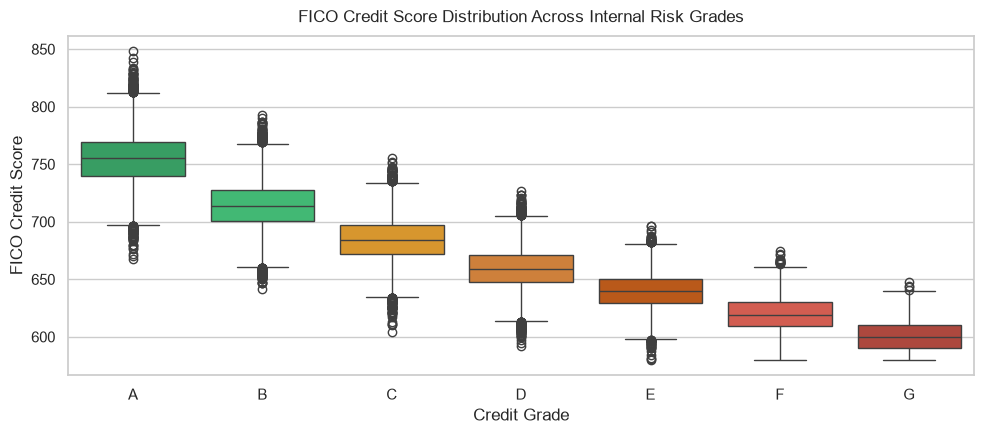

In [16]:
plt.figure(figsize=(10, 4.5))
sns.boxplot(data=df, x='Grade', y='FicoScore', order=['A','B','C','D','E','F','G'], palette=palette_gr)
plt.title('FICO Credit Score Distribution Across Internal Risk Grades', fontsize=12, pad=10)
plt.xlabel('Credit Grade')
plt.ylabel('FICO Credit Score')
plt.tight_layout()
plt.show()


## 17. Borrower Annual Income Metrics & Upper-Tail Dispersion
Evaluate borrower earning capacity and extreme income values.


In [17]:
print(f'Median Annual Income       : ${df["AnnualIncome"].median():,.2f}')
print(f'Mean Annual Income         : ${df["AnnualIncome"].mean():,.2f}')
print(f'99th Percentile Income     : ${df["AnnualIncome"].quantile(0.99):,.2f}')
print(f'Max Income Recorded        : ${df["AnnualIncome"].max():,.2f}')


Median Annual Income       : $62,800.00
Mean Annual Income         : $69,564.13
99th Percentile Income     : $179,000.00
Max Income Recorded        : $350,000.00


## 18. Visual 4: Annual Income Log-Distribution Histogram
Visualizing borrower earning distribution on log scale.


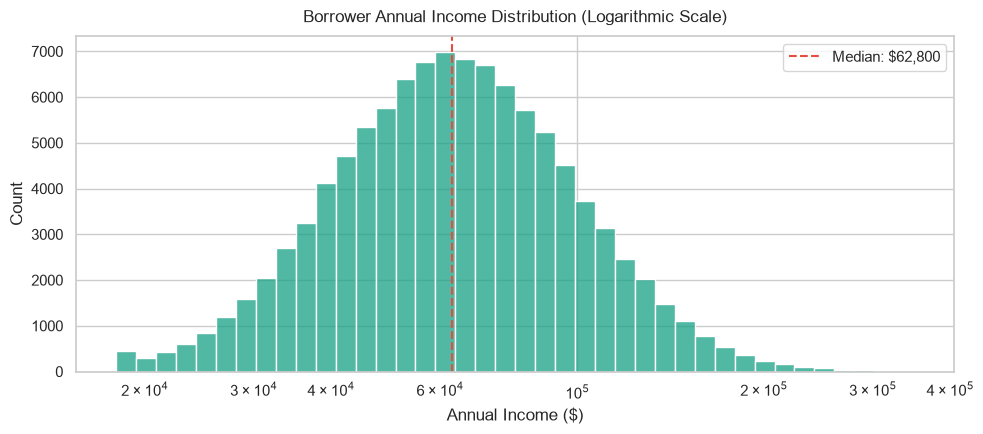

In [18]:
plt.figure(figsize=(10, 4.5))
sns.histplot(df['AnnualIncome'], bins=40, color='#16a085', log_scale=True)
plt.axvline(df['AnnualIncome'].median(), color='#e74c3c', linestyle='--', label=f'Median: ${df["AnnualIncome"].median():,.0f}')
plt.title('Borrower Annual Income Distribution (Logarithmic Scale)', fontsize=12, pad=10)
plt.xlabel('Annual Income ($)')
plt.legend()
plt.tight_layout()
plt.show()


## 19. Debt-to-Income (DTI) Leverage & Distressed Borrower Identification
Evaluate borrower leverage ratios exceeding 25%.


In [19]:
print(f'Median DTI Ratio             : {df["DTI"].median():.1f}%')
print(f'Mean DTI Ratio               : {df["DTI"].mean():.1f}%')
print(f'Proportion with DTI > 25.0%  : {(df["DTI"] > 25.0).mean() * 100:.2f}%')
print(f'Distressed Accounts (DTI>35%): {(df["DTI"] > 35.0).sum():,} accounts')


Median DTI Ratio             : 19.0%
Mean DTI Ratio               : 19.3%
Proportion with DTI > 25.0%  : 19.34%
Distressed Accounts (DTI>35%): 1,440 accounts


## 20. Visual 5: Debt-to-Income (DTI) Distribution Histogram
Plotting DTI distribution with credit stress threshold.


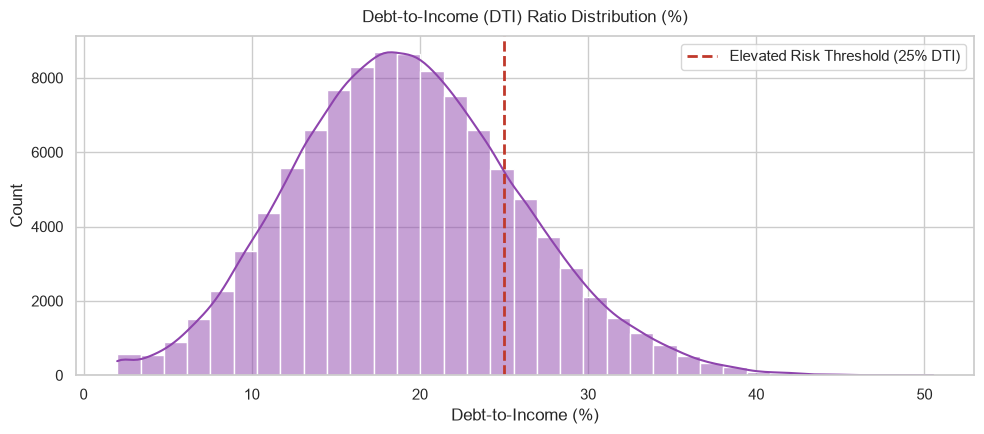

In [20]:
plt.figure(figsize=(10, 4.5))
sns.histplot(df['DTI'], bins=35, kde=True, color='#8e44ad')
plt.axvline(25.0, color='#c0392b', linestyle='--', lw=2, label='Elevated Risk Threshold (25% DTI)')
plt.title('Debt-to-Income (DTI) Ratio Distribution (%)', fontsize=12, pad=10)
plt.xlabel('Debt-to-Income (%)')
plt.legend()
plt.tight_layout()
plt.show()


## 21. Terminal Loan Outcome Breakdown & Default Volume
Tabulating loan accounts across terminal performance statuses.


In [21]:
stat_tab = df['LoanStatus'].value_counts().reset_index()
stat_tab.columns = ['LoanStatus', 'AccountCount']
stat_tab['Share_Pct'] = (stat_tab['AccountCount'] / stat_tab['AccountCount'].sum() * 100).round(2)
stat_tab


,LoanStatus,AccountCount,Share_Pct
0,Fully Paid,63545,60.52
1,Current,25450,24.24
2,Charged Off,11954,11.38
3,Default,1834,1.75
4,Late (31-120 days),1558,1.48
5,In Grace Period,659,0.63


## 22. Visual 6: Quantitative Financial Risk Correlation Heatmap
Diagnosing inter-variable correlations between credit drivers and loss.


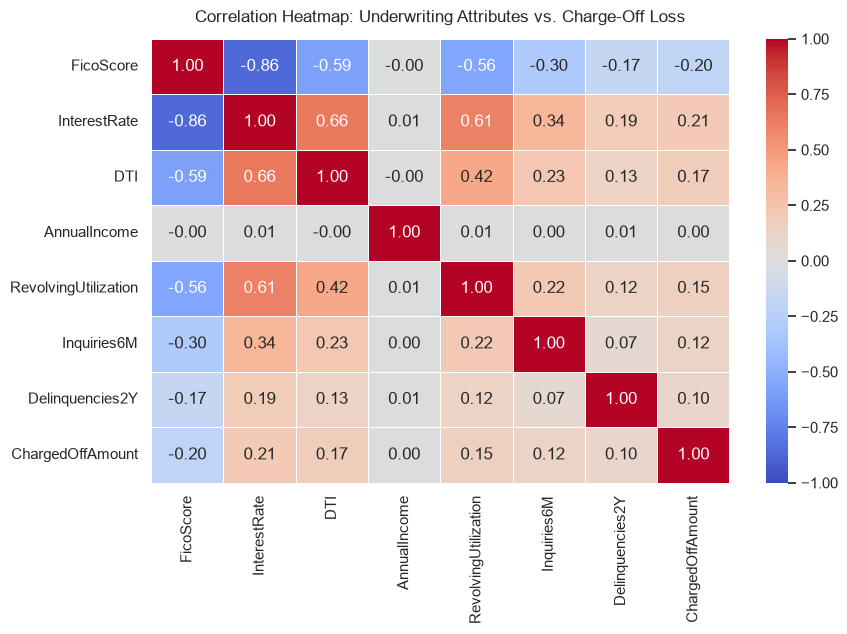

In [22]:
num_cols = ['FicoScore', 'InterestRate', 'DTI', 'AnnualIncome', 'RevolvingUtilization', 'Inquiries6M', 'Delinquencies2Y', 'ChargedOffAmount']
corr_m = df[num_cols].corr().round(3)

plt.figure(figsize=(9, 6.5))
sns.heatmap(corr_m, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Correlation Heatmap: Underwriting Attributes vs. Charge-Off Loss', fontsize=12, pad=12)
plt.tight_layout()
plt.show()
